# Representation Depth

**Question:** After a complete target change, how does relearning speed differ between a linear problem, one hidden layer, and two hidden layers?

Each stream has 21 independent ±1 inputs and 10 linear outputs with Gaussian noise of standard deviation 1. Replace **all teacher weights every 50,000 examples**, for ten teachers in total. Teachers do not recur. The learner keeps its weights, optimizer state, and centering statistics; no change notification is provided.

Learner depth matches teacher depth: **linear**, **10 LTUs**, or **10 LTUs → 10 LTUs**, with ordinary sequential connections and no skips. Every learner bias is an explicit constant-1 input. Teacher first-layer and readout weights are ±1. At depth two, the second layer reads bipolar first-layer bits and uses independent uniform [-1, 1] weights, avoiding ties and keeping its inputs balanced. Learner biases allow the same functions to be represented using either raw or centered LTU features.

Linear teacher weights are scaled by sqrt(10 / (4 × 21)), giving signal variance 2.5, the shallow teacher's nominal variance. Hidden-feature correlations still make signal variance differ between teachers; these curves compare the three problem families, not depth at an identical target function. RMSE 1 is attainable within each block; unannounced replacements impose additional online error.

Compare all five SGD step sizes with network Autostep, using the same five seeds throughout: **meta step 0.02, initial step 1e-5**, small hidden initialization, and **uncompensated** centering. Centering rate is 1e-3; Autostep uses squared-input normalization with time constant 1e4. The linear learner has no hidden activation to center. SGD uses fan-in initialization and the sigmoid surrogate for LTUs. Readouts start at zero only at the beginning of the stream.

Plot RMSE against actual training steps, including the initial teacher and preserving the order of later teachers. Do not average replacements together. Show all 500k steps, with each depth on its own row. The first figure shows every SGD rate; the second compares the best observed SGD rate at each depth with Autostep, using final-100k mean per-seed RMSE to choose the rate without retraining. Matching seed IDs share inputs and noise across methods and depths; a fresh teacher is generated independently of the learner.

In [1]:
from functools import partial
from pathlib import Path
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problem
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10

# Autostep: uncompensated centering and small hidden initialization.
INIT_RATE, META_RATE, EMA_RATE = 1e-5, .02, 1e-3

# Training
PERIOD = 50_000
BLOCKS = 10
WINDOW = 100
SGD_EXPONENTS = (-12, -10, -8, -6, -4)
SGD_RATES = [2.**p for p in SGD_EXPONENTS]
N_SEEDS = 5
assert PERIOD % WINDOW == 0

## Task

In [3]:
def teacher(key, depth):
    """Fresh independent teacher. Depth one matches the original simple GEOFF."""
    keys = jax.random.split(key, 3)
    first = jax.random.rademacher(keys[0], (WIDTH, N_INPUTS), dtype=jnp.float32)
    # Continuous second-layer weights avoid ties on the even-width binary inputs.
    second = jax.random.uniform(keys[1], (WIDTH, WIDTH), minval=-1., maxval=1.)
    fan_in = N_INPUTS if depth == 0 else WIDTH
    out = jax.random.rademacher(keys[2], (N_OUTPUTS, fan_in), dtype=jnp.float32)
    if depth == 0:
        # Match the shallow teacher's nominal per-output signal variance (10/4).
        out = out * np.sqrt(WIDTH / (4 * N_INPUTS))
    return first, second, out


def target(weights, x, depth):
    first, second, out = weights
    if depth > 0:
        x = (first @ x > 0).astype(jnp.float32)
    if depth == 2:
        x = (second @ (2 * x - 1) > 0).astype(jnp.float32)
    return out @ x

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True,
                       tau=1e4, version='squared_inputs')

class Learner(NamedTuple):
    weights: tuple
    opt: object
    means: tuple
    slopes: tuple


def init_learner(key, widths, method):
    weights = []
    fan_in = N_INPUTS
    for width, subkey in zip(widths, jax.random.split(key, len(widths))):
        bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / fan_in)
        w = jax.random.uniform(subkey, (width, fan_in + 1), minval=-bound, maxval=bound)
        weights.append(w.at[:, -1].set(0.))
        fan_in = width
    weights.append(jnp.zeros((N_OUTPUTS, fan_in + 1)))
    weights = tuple(weights)
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   tuple(jnp.full(w.shape[0], .5) for w in weights[:-1]),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]))


def forward(weights, x, learner, method):
    sources, means, slopes = [], [], []
    for w, mean, slope in zip(weights[:-1], learner.means, learner.slopes):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        x = ltu(z)
        if method == 'Autostep':
            # Same uncompensated centering and centered surrogate as network_autostep.
            mean = mean + EMA_RATE * (jax.lax.stop_gradient(x) - mean)
            sigmoid = jax.nn.sigmoid(z)
            derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))
            slope = slope + EMA_RATE * (derivative[:, None] * jax.lax.stop_gradient(source) - slope)
            correction = jnp.sum(slope * w, axis=1)
            x = x - mean + (jax.lax.stop_gradient(correction) - correction)
        means.append(mean)
        slopes.append(slope)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes))


def update(learner, x, y, method, rate):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, method)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, means, slopes)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -rate * g, grads), None
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, means, slopes), 2 * loss_value / N_OUTPUTS

## Training

In [5]:
def train(seed, rate, method, depth):
    teacher_key, learner_key, _, rng = jax.random.split(jax.random.PRNGKey(seed), 4)
    learner = init_learner(learner_key, (WIDTH,) * depth, method)

    def block(carry, block_id):
        # Only the teacher changes. The learner and its optimizer carry on.
        weights = teacher(jax.random.fold_in(teacher_key, block_id), depth)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(weights, x, depth) + jax.random.normal(noise_key, (N_OUTPUTS,))
            learner, mse = update(learner, x, y, method, rate)
            return (learner, rng), mse

        def record(carry, _):
            carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
            return carry, mse.mean()
        return jax.lax.scan(record, carry, length=PERIOD // WINDOW)

    _, mse = jax.lax.scan(block, (learner, rng), jnp.arange(BLOCKS))
    return mse


@partial(jax.jit, static_argnames=('method', 'depth'))
def train_many(seeds, rates, method, depth):
    one = partial(train, method=method, depth=depth)
    return jax.vmap(jax.vmap(one, in_axes=(0, None)), in_axes=(None, 0))(seeds, rates)


def run(method, depth, rates=None):
    started = perf_counter()
    rates = jnp.asarray([INIT_RATE] if rates is None else rates, dtype=jnp.float32)
    mse = np.asarray(train_many(jnp.arange(N_SEEDS), rates, method, depth))
    assert np.isfinite(mse).all()
    print(f'{method}, depth {depth}: {perf_counter() - started:.1f}s including compilation')
    return mse

In [6]:
started = perf_counter()
runs = {}
for depth in (0, 1, 2):
    sgd = run('SGD', depth=depth, rates=SGD_RATES)
    autostep = run('Autostep', depth=depth)
    runs[f'sgd_{depth}'] = sgd
    runs[f'autostep_{depth}'] = autostep
seconds = perf_counter() - started
np.savez_compressed(RESULTS / 'representation_depth.npz', **runs, rates=SGD_RATES,
                    period=PERIOD, window=WINDOW, seconds=seconds)
print(f'Complete comparison: {seconds:.1f}s including compilation.')
assert seconds < 120, 'Simplify the experiment before extending it.'

SGD, depth 0: 6.6s including compilation
Autostep, depth 0: 5.6s including compilation
SGD, depth 1: 7.1s including compilation
Autostep, depth 1: 11.0s including compilation
SGD, depth 2: 10.4s including compilation
Autostep, depth 2: 15.5s including compilation
Complete comparison: 56.1s including compilation.


## Plots

Depth 0, SGD $2^{-12}$: first 100k 1.0731; last 100k 1.0982
Depth 0, SGD $2^{-10}$: first 100k 1.0240; last 100k 1.0308
Depth 0, SGD $2^{-8}$: first 100k 1.0270; last 100k 1.0289
Depth 0, SGD $2^{-6}$: first 100k 1.1001; last 100k 1.1008
Depth 0, SGD $2^{-4}$: first 100k 1.7890; last 100k 1.7889
Depth 0, Autostep: first 100k 1.0479; last 100k 1.0246
Comparison uses SGD 2^(-8), chosen by final-100k RMSE.
Depth 1, SGD $2^{-12}$: first 100k 1.6263; last 100k 1.6656
Depth 1, SGD $2^{-10}$: first 100k 1.4820; last 100k 1.5123
Depth 1, SGD $2^{-8}$: first 100k 1.2519; last 100k 1.3206
Depth 1, SGD $2^{-6}$: first 100k 1.1699; last 100k 1.2626
Depth 1, SGD $2^{-4}$: first 100k 1.2967; last 100k 1.5374
Depth 1, Autostep: first 100k 1.4461; last 100k 1.2726
Comparison uses SGD 2^(-6), chosen by final-100k RMSE.
Depth 2, SGD $2^{-12}$: first 100k 1.8037; last 100k 1.8228
Depth 2, SGD $2^{-10}$: first 100k 1.6942; last 100k 1.7224
Depth 2, SGD $2^{-8}$: first 100k 1.6011; last 100k 1.6356
Depth 2

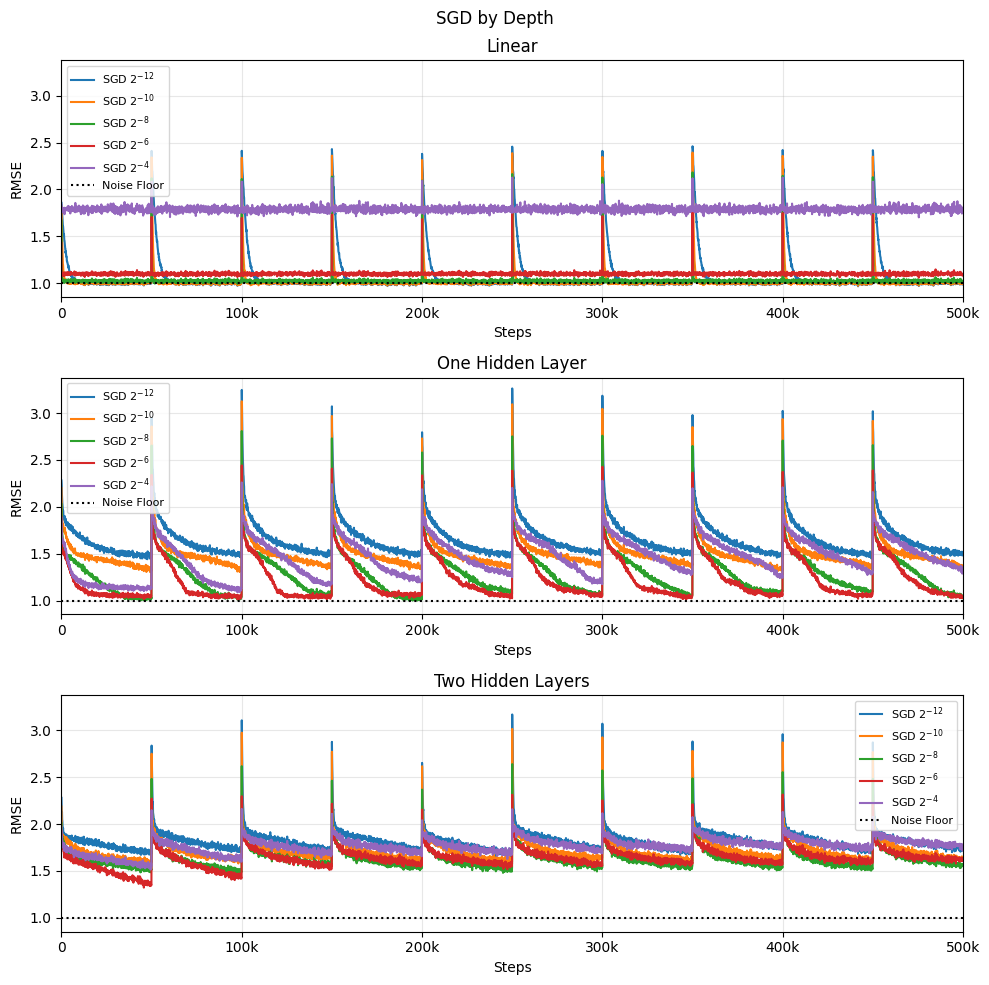

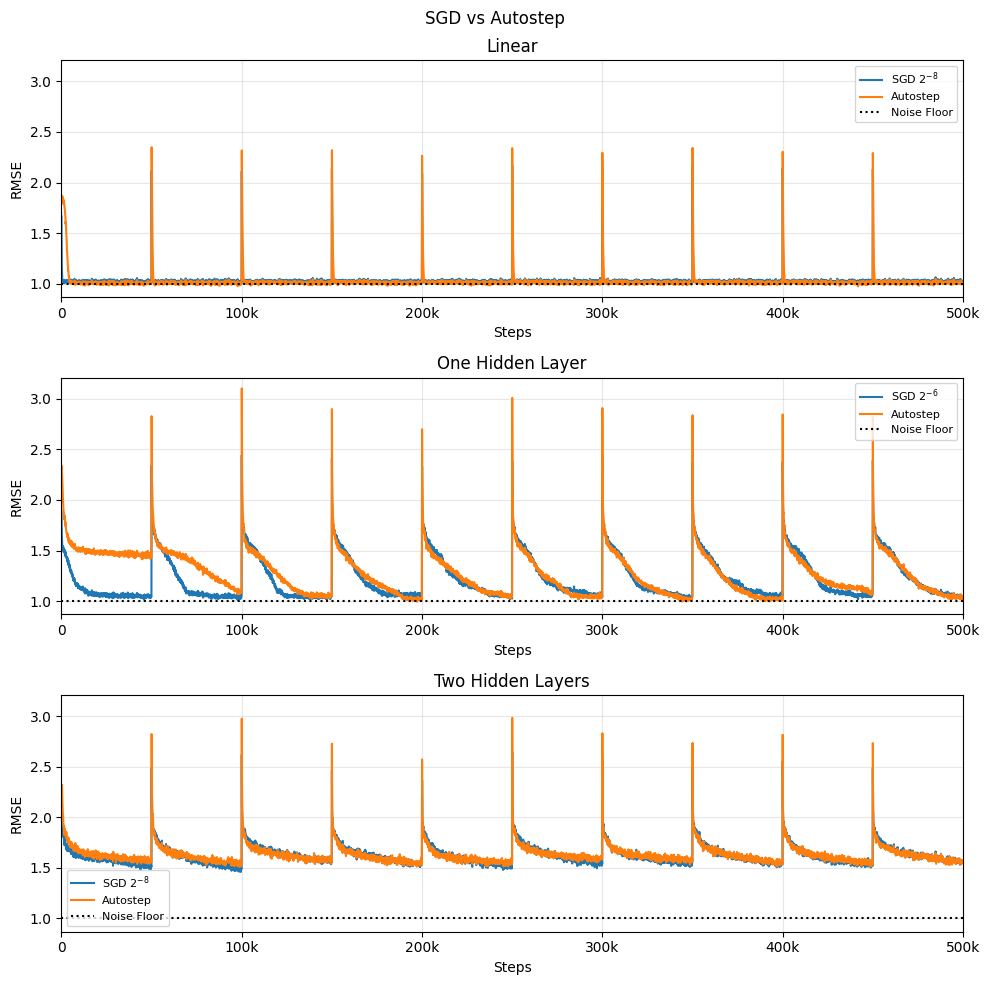

In [7]:
steps = np.arange(1, BLOCKS * PERIOD // WINDOW + 1) * WINDOW
sgd_labels = [rf'SGD $2^{{{p}}}$' for p in SGD_EXPONENTS]
score_blocks = 100_000 // PERIOD
best = {depth: int(np.argmin(np.sqrt(runs[f'sgd_{depth}'][:, :, -score_blocks:].mean(axis=(2, 3))).mean(axis=1)))
        for depth in (0, 1, 2)}


def plot_depths(comparison):
    fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, sharey=True)
    for depth, ax in enumerate(axes):
        if comparison:
            index = best[depth]
            curves = [(sgd_labels[index], runs[f'sgd_{depth}'][index]),
                      ('Autostep', runs[f'autostep_{depth}'][0])]
        else:
            curves = list(zip(sgd_labels, runs[f'sgd_{depth}']))
        for label, values in curves:
            values = values.reshape(len(values), -1)
            ax.plot(steps, np.sqrt(values).mean(axis=0), label=label)
        ax.axhline(1., color='black', ls=':', label='Noise Floor')
        ax.set(title=('Linear', 'One Hidden Layer', 'Two Hidden Layers')[depth],
               xlabel='Steps', ylabel='RMSE', xlim=(0, 500_000))
        ticks = np.arange(0, 500_001, 100_000)
        ax.set_xticks(ticks, ['0' if t == 0 else f'{t // 1000}k' for t in ticks])
        ax.tick_params(axis='x', labelbottom=True)
        ax.grid(True, alpha=.3)
        ax.legend(fontsize=8)
    fig.suptitle('SGD vs Autostep' if comparison else 'SGD by Depth')
    fig.tight_layout()
    plt.show()


plot_depths(comparison=False)
plot_depths(comparison=True)
for depth in (0, 1, 2):
    curves = list(zip(sgd_labels, runs[f'sgd_{depth}'])) + [('Autostep', runs[f'autostep_{depth}'][0])]
    for label, values in curves:
        first = np.sqrt(values[:, :score_blocks].mean(axis=(1, 2))).mean()
        last = np.sqrt(values[:, -score_blocks:].mean(axis=(1, 2))).mean()
        print(f'Depth {depth}, {label}: first 100k {first:.4f}; last 100k {last:.4f}')
    print(f'Comparison uses SGD 2^({SGD_EXPONENTS[best[depth]]}), chosen by final-100k RMSE.')


Five paired seeds per configuration; no uncertainty bands. Curves show all 500k steps in order, with a new teacher every 50k. The comparison uses the SGD rate with the lowest final-100k RMSE, without retraining.

**Result (56.1s on GPU):** Final-100k RMSE is 1.025 / 1.273 / 1.637 for Autostep on linear / one-layer / two-layer targets. The comparison SGD rates are $2^{-8}$ / $2^{-6}$ / $2^{-8}$, with scores 1.029 / 1.263 / 1.636. All curves include every teacher switch.
